In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input/datasets/kmader"):
    print(root, "|", len(dirs), "dossiers |", len(files), "fichiers")
    for f in files[:5]:
        print("   ", f)
    if root.count("/") > 6:
        break

/kaggle/input/datasets/kmader | 1 dossiers | 0 fichiers
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000 | 4 dossiers | 5 fichiers
    hmnist_8_8_RGB.csv
    hmnist_28_28_RGB.csv
    hmnist_8_8_L.csv
    hmnist_28_28_L.csv
    HAM10000_metadata.csv
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1 | 0 dossiers | 5000 fichiers
    ISIC_0028933.jpg
    ISIC_0028394.jpg
    ISIC_0027799.jpg
    ISIC_0028100.jpg
    ISIC_0027960.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_1 | 0 dossiers | 5000 fichiers
    ISIC_0028933.jpg
    ISIC_0028394.jpg
    ISIC_0027799.jpg
    ISIC_0028100.jpg
    ISIC_0027960.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2 | 0 dossiers | 5015 fichiers
    ISIC_0030912.jpg
    ISIC_0030585.jpg
    ISIC_0033697.jpg
    ISIC_0030062.jpg
    ISIC_0031213.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/ham10000_images_part_2 | 0 dossiers | 5015 f

(10015, 7)
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
dx
nv       66.9
mel      11.1
bkl      11.0
bcc       5.1
akiec     3.3
vasc      1.4
df        1.1
Name: count, dtype: float64


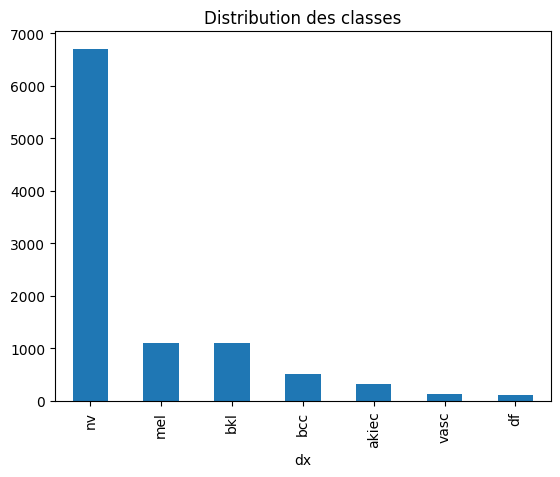

Images: 10015 | Lésions: 7470


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
df = pd.read_csv(f"{BASE}/HAM10000_metadata.csv")

print(df.shape)
print(df.head())

counts = df["dx"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

counts.plot(kind="bar", title="Distribution des classes")
plt.show()

print("Images:", df["image_id"].nunique(), "| Lésions:", df["lesion_id"].nunique())

In [4]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

paths = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    d = f"{BASE}/{part}"
    for f in os.listdir(d):
        paths[f.replace(".jpg", "")] = f"{d}/{f}"
df["path"] = df["image_id"].map(paths)
assert df["path"].notna().all()

def split(data, n_splits, seed=42):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, part = next(sgkf.split(data, data["dx"], groups=data["lesion_id"]))
    return data.iloc[rest], data.iloc[part]

train_val, test = split(df, 10)
train, val = split(train_val, 9)

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, len(d), "images |", d["lesion_id"].nunique(), "lésions")
    print((d["dx"].value_counts(normalize=True) * 100).round(1).to_dict())

assert not set(train.lesion_id) & set(val.lesion_id)
assert not set(train.lesion_id) & set(test.lesion_id)
assert not set(val.lesion_id) & set(test.lesion_id)
print("Aucune fuite entre les splits")

os.makedirs("/kaggle/working/splits", exist_ok=True)
train.to_csv("/kaggle/working/splits/train.csv", index=False)
val.to_csv("/kaggle/working/splits/val.csv", index=False)
test.to_csv("/kaggle/working/splits/test.csv", index=False)

train 8013 images | 5976 lésions
{'nv': 67.4, 'bkl': 11.0, 'mel': 11.0, 'bcc': 5.0, 'akiec': 3.0, 'vasc': 1.5, 'df': 1.2}
val 1010 images | 747 lésions
{'nv': 65.0, 'mel': 12.0, 'bkl': 11.6, 'bcc': 5.0, 'akiec': 4.5, 'df': 1.1, 'vasc': 0.9}
test 992 images | 747 lésions
{'nv': 65.6, 'mel': 11.2, 'bkl': 10.2, 'bcc': 6.7, 'akiec': 3.8, 'vasc': 1.5, 'df': 1.0}
Aucune fuite entre les splits
